# Experiment 9 — Decision Trees and Random Forest (Titanic Dataset)

**Covers:** Full decision tree, restricted decision tree, tree plot, Random Forest, OOB score, evaluation, confusion matrices, ROC curves, feature importance, permutation importance, effect of tree count and CSV export.

**Dataset:** **Titanic** – `train.csv` from the Kaggle Titanic competition ([kaggle.com/c/titanic](https://www.kaggle.com/competitions/titanic/data)), 891 passengers, columns `PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked`.

**Data file:** keep `train.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\train.csv")`).

**Remember:** Split → Three models → Metrics → ROC → Tree plot → OOB → Feature importance → Tree count → Compare.

Target: `Survived`. Same data preparation as Experiment 8.

## Import libraries and load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

df = pd.read_csv("train.csv")

## 1. Same data as Experiment 8

In [2]:
cols = ["Sex", "Age", "Fare", "Pclass", "SibSp", "Parch"]
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
data = df[cols + ["Survived"]].dropna()

X = data[cols]
y = data["Survived"]

print("Class mapping: 0 = Died, 1 = Survived")
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", len(X_train), "Test:", len(X_test))

Class mapping: 0 = Died, 1 = Survived
Survived
0    424
1    290
Name: count, dtype: int64
Train: 571 Test: 143


## 2. Models (full tree, small tree, random forest)


 Full Tree
              precision    recall  f1-score   support

           0       0.77      0.78      0.77        85
           1       0.67      0.66      0.66        58

    accuracy                           0.73       143
   macro avg       0.72      0.72      0.72       143
weighted avg       0.73      0.73      0.73       143



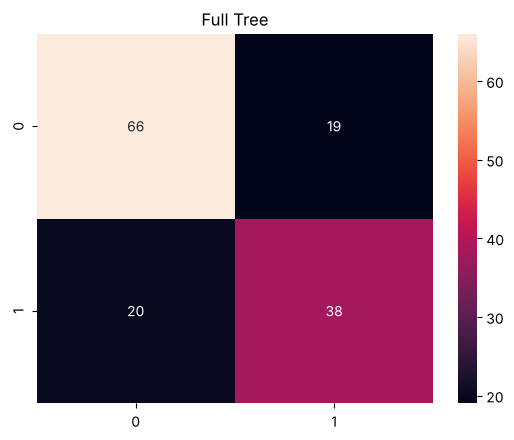


 Small Tree
              precision    recall  f1-score   support

           0       0.76      0.84      0.79        85
           1       0.71      0.60      0.65        58

    accuracy                           0.74       143
   macro avg       0.73      0.72      0.72       143
weighted avg       0.74      0.74      0.74       143



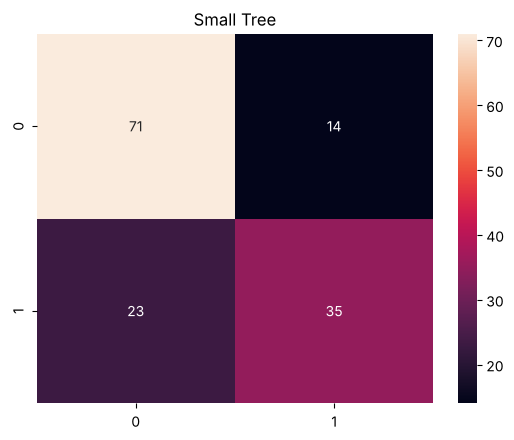


 Random Forest
              precision    recall  f1-score   support

           0       0.79      0.81      0.80        85
           1       0.71      0.69      0.70        58

    accuracy                           0.76       143
   macro avg       0.75      0.75      0.75       143
weighted avg       0.76      0.76      0.76       143



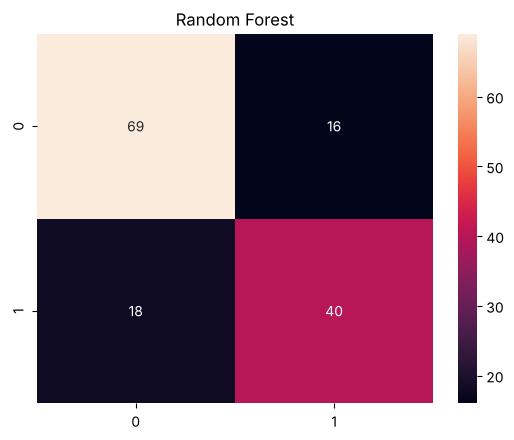

In [3]:
models = {
    "Full Tree": DecisionTreeClassifier(random_state=42),
    "Small Tree": DecisionTreeClassifier(
        max_depth=5, min_samples_split=10,
        min_samples_leaf=5, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, oob_score=True, random_state=42, n_jobs=-1
    )
}

results = []
roc = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append([
        name,
        accuracy_score(y_train, model.predict(X_train)),
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred),
        roc_auc_score(y_test, prob)
    ])

    print("\n", name)
    print(classification_report(y_test, pred))

    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d")
    plt.title(name)
    plt.show()

    fpr, tpr, _ = roc_curve(y_test, prob)
    roc[name] = (fpr, tpr)

## 3. ROC curves

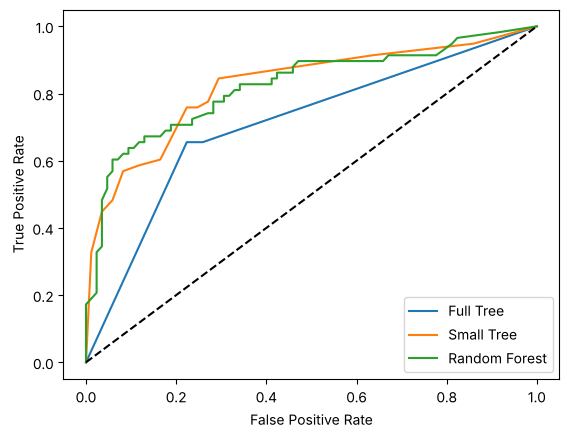

In [4]:
for name, (fpr, tpr) in roc.items():
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

## 4. Tree details and plot

Full Tree Depth: 17 Leaves: 133
Small Tree Depth: 5 Leaves: 24


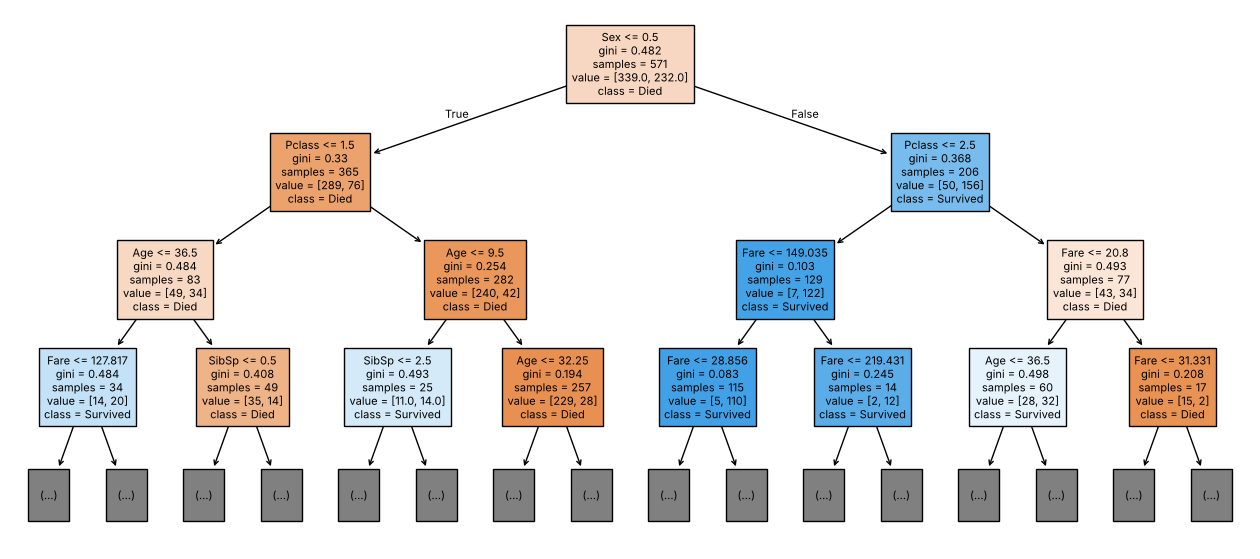

In [5]:
for name in ["Full Tree", "Small Tree"]:
    tree = models[name]
    print(name, "Depth:", tree.get_depth(), "Leaves:", tree.get_n_leaves())

plt.figure(figsize=(16, 7))
plot_tree(models["Small Tree"], feature_names=cols,
          class_names=["Died", "Survived"],
          max_depth=3, filled=True, fontsize=8)
plt.show()

## 5. Random Forest OOB score
Out-of-bag score = accuracy on the training rows each tree did not see.

In [6]:
rf = models["Random Forest"]
print("OOB Score:", rf.oob_score_)

OOB Score: 0.8231173380035026


## 6. Feature importance

            Tree    Forest  Permutation  Permutation SD
Sex     0.294632  0.250175     0.151748        0.030650
Age     0.245890  0.277039     0.019580        0.013194
Fare    0.233177  0.289149     0.011189        0.016310
Pclass  0.131638  0.097835     0.030070        0.017979
SibSp   0.076981  0.047678    -0.007692        0.016084
Parch   0.017682  0.038124    -0.016084        0.014348


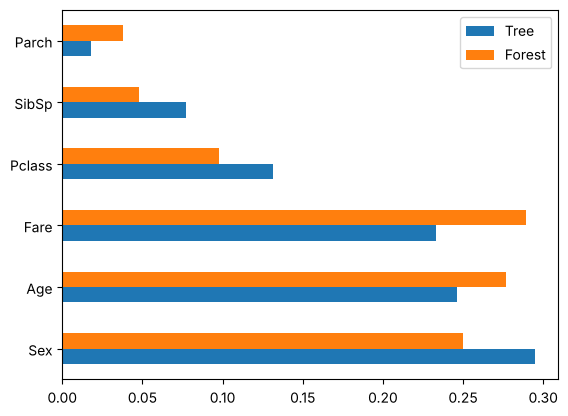

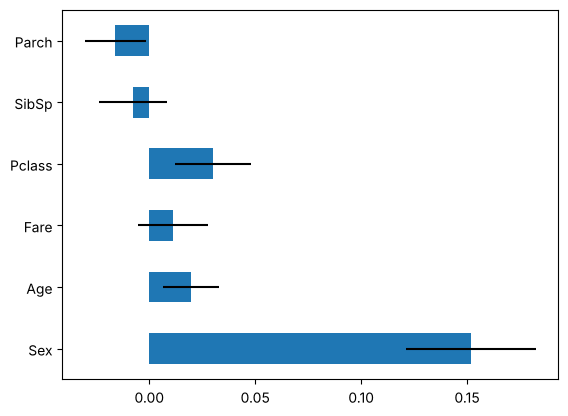

In [7]:
perm = permutation_importance(
    rf, X_test, y_test, n_repeats=10, random_state=42
)

importance = pd.DataFrame({
    "Tree": models["Full Tree"].feature_importances_,
    "Forest": rf.feature_importances_,
    "Permutation": perm.importances_mean,
    "Permutation SD": perm.importances_std
}, index=cols)

print(importance)

importance[["Tree", "Forest"]].plot(kind="barh")
plt.show()

importance["Permutation"].plot(
    kind="barh", xerr=importance["Permutation SD"]
)
plt.show()

## 7. Effect of number of trees (5-fold CV)

   Trees  Accuracy        F1       AUC
0     10  0.800336  0.743565  0.841497
1     25  0.831854  0.789007  0.859818
2     50  0.831854  0.788038  0.861684
3    100  0.824836  0.779256  0.864652
4    200  0.823097  0.777436  0.867405


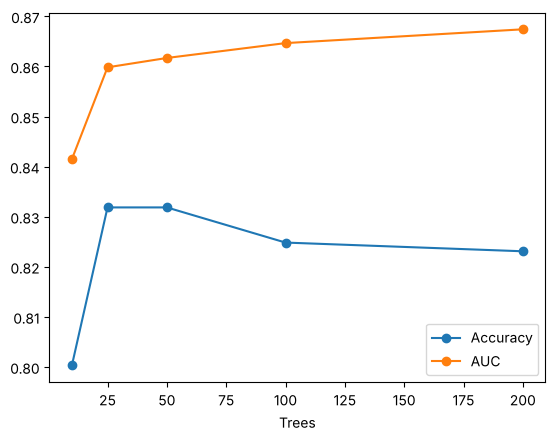

In [8]:
rows = []
for n in [10, 25, 50, 100, 200]:
    model = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    cv = cross_validate(model, X_train, y_train, cv=5,
                        scoring=["accuracy", "f1", "roc_auc"])
    rows.append([n, cv["test_accuracy"].mean(),
                 cv["test_f1"].mean(), cv["test_roc_auc"].mean()])

tree_results = pd.DataFrame(
    rows, columns=["Trees", "Accuracy", "F1", "AUC"]
)
print(tree_results)

tree_results.plot(x="Trees", y=["Accuracy", "AUC"], marker="o")
plt.show()

## 8. Comparison and save

               Train Accuracy  Accuracy  Precision    Recall        F1  \
Model                                                                    
Full Tree            0.989492  0.727273   0.666667  0.655172  0.660870   
Small Tree           0.858144  0.741259   0.714286  0.603448  0.654206   
Random Forest        0.989492  0.762238   0.714286  0.689655  0.701754   

                    AUC  
Model                    
Full Tree      0.709736  
Small Tree     0.823428  
Random Forest  0.822414  


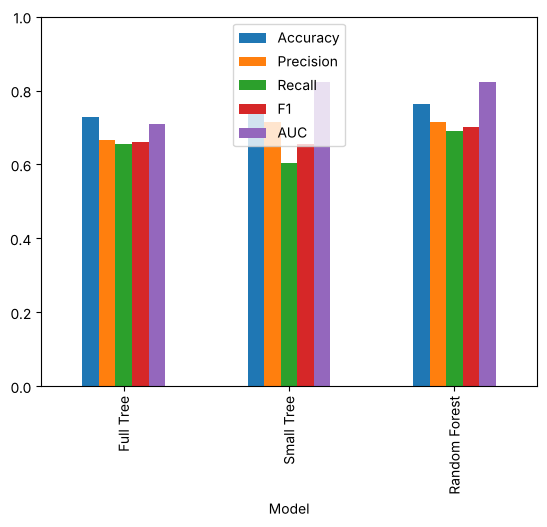

Saved tree_results.csv, feature_importance.csv, tree_count.csv


In [9]:
result = pd.DataFrame(results, columns=[
    "Model", "Train Accuracy", "Accuracy",
    "Precision", "Recall", "F1", "AUC"
]).set_index("Model")

print(result)
result.drop(columns="Train Accuracy").plot(kind="bar", ylim=(0, 1))
plt.show()

result.to_csv("tree_results.csv")
importance.to_csv("feature_importance.csv")
tree_results.to_csv("tree_count.csv", index=False)
print("Saved tree_results.csv, feature_importance.csv, tree_count.csv")

## Result / Conclusion
- The full tree (depth 17, 133 leaves) memorises the training data (train accuracy 0.989) but scores only 0.727 on the test set – **over-fitting**.
- The small tree (depth 5) generalises better: test accuracy 0.741, AUC 0.823. Its first split is on **Sex**, then Pclass, Age and Fare.
- The **Random Forest** gives the best accuracy (0.762) and F1 (0.702), with AUC 0.822 and OOB score 0.823.
- Permutation importance shows **Sex** matters most by far (0.152 drop in accuracy when shuffled). CV accuracy peaks at about 0.83 with 25–50 trees.